# Análise Exploratória sobre dados de exoplanetas catalogados pelo NASA

## Profa. Cibele Russo (ICMC USP)

### Assistentes:
- Davi Gabriel Domingues
- Arthur Domingues Rios
- Matheus Vieira Fernandes
- Gabriel Inumaru Esteves
- Arthur Amorim Ruschel

### Base de dados
Este conjunto de dados abrange, sem duplicatas ou registros corrompidos, os 6445 exoplanetas (planeta que orbita uma estrela que não é o nosso Sol) confirmados catalogados pelo NASA Exoplanet Archive (IPAC/Caltech) até outubro de 2026, contemplando dinâmicas orbitais, propriedades planetárias globais, parâmetros das estrelas hospedeiras e métricas multidimensionais de habitabilidade.

## Análise exploratória de dados


A análise exploratória de dados visa descobrir aspectos de maior interesse através da exploração dos dados, com estes sendo representados de modo a destacar padrões que podem ou não se confirmar inferencialmente.


In [123]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [124]:
df = pd.read_csv('exoplanetas_colunas_selecionadas.csv')

## Detalhando as variáveis do conjunto de dados dos exoplanetas:

- **nome_planeta:**

  Nome oficial (IAU) do exoplaneta ou designação atribuída por ocasião de sua descoberta. São exemplos "CD-35 2722 B b" e "DMPP-2 c".
- **nome_estrela_primaria:**
  
  Nome da estrela principal em torno da qual o planeta orbita. São exemplos "CD-35 2722 B" e "DMPP-2".
- **metodo_descoberta:**

  Método principal de detecção observacional, podendo ser: "Trânsito", baseado em diminuições na luz das estrelas causadas por planetas em órbita; "Microlente Gravitacional", em que as massas de exoplanetas e suas estrelas distorcem o tecido do espaço-tempo, fazendo com que a luz de estrelas de fundo siga a curvatura, permitindo a detecção de novos sistemas; "Velocidade Radial", que detecta exoplanetas medindo as pequenas alterações na luz de uma estrela (por efeito Doppler) causadas pela oscilação gravitacional que o planeta exerce sobre ela; ou "Outros".

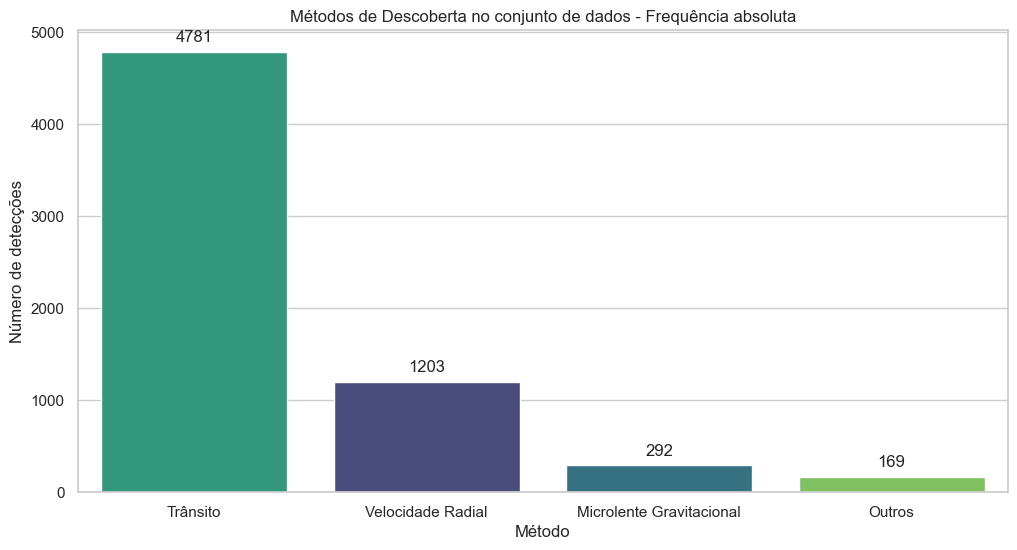

In [125]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

ay = sns.countplot(
    data=df,
    x='metodo_descoberta',
    order=df['metodo_descoberta'].value_counts().index,
    palette='viridis',
    hue='metodo_descoberta',
    legend=False,
)
for container in ay.containers:
    ay.bar_label(container, padding=5)

plt.title('Métodos de Descoberta no conjunto de dados - Frequência absoluta')
plt.ylabel('Número de detecções')
plt.xlabel('Método')

plt.show()

- **ano_descoberta:**
  
  Ano em que a descoberta do planeta foi oficialmente anunciada e confirmada (1992 a 2026).

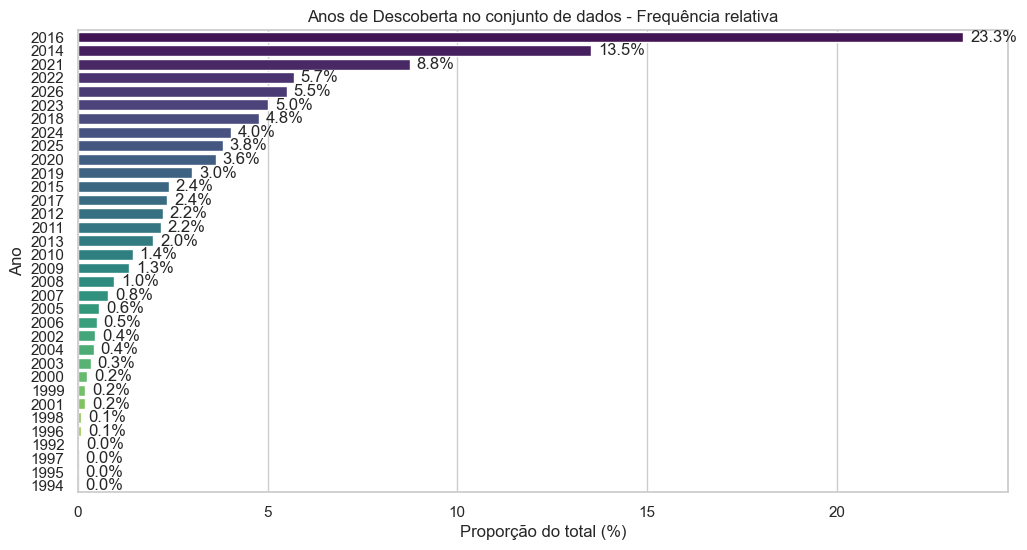

In [126]:
freq_relativa = df['ano_descoberta'].value_counts(normalize=True) * 100
df_perc = freq_relativa.reset_index()
df_perc.columns = ['ano_descoberta', 'porcentagem']
df_perc['ano_descoberta'] = df_perc['ano_descoberta'].astype(str)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df_perc,
    x='porcentagem',
    y='ano_descoberta',
    order=df_perc['ano_descoberta'],
    palette='viridis',
    hue='ano_descoberta',
    legend=False,
    orient='h'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=5)

plt.title('Anos de Descoberta no conjunto de dados - Frequência relativa')
plt.xlabel('Proporção do total (%)')
plt.ylabel('Ano')

plt.show()

- **observatorio_descoberta:**

  Missão espacial ou observatório astronômico em solo ao qual se atribui a detecção inicial, por exemplo, "Satélite de Pesquisa de Exoplanetas em Trânsito (TESS)".

- **periodo_orbital:**

  Período orbital em que o planeta completa uma volta ao redor de sua estrela, expresso em dias terrestres.
- **raio_planetario:**

  Raio do planeta medido em unidades de raios terrestres (o raio da Terra mede cerca de 6371 quilômetros).
- **massa_planetaria:**

  Massa do planeta ou massa mínima, expressa em unidades de massas terrestres (a massa da Terra é por volta de 5,97 sextilhões de toneladas).
- **temp_equilibrio_superf_planetaria:**

  Temperatura de equilíbrio da superfície planetária em Kelvin (K = ºC + 273,15).
- **temp_superf_estelar:**

  Temperatura da superfície (fotosfera) da estrela, em Kelvin.
- **distancia_sistema:**

  Distância do Sistema Solar a esse sistema estelar, medida em parsecs (um parsec equivale a 3,26 anos-luz, 206000 unidades astronômicas, ou então 30,9 trilhões de quilômetros).

- **arquetipo_planetario:**

  Arquétipo (classe) estrutural do planeta, o qual pode ser: "Sub-Netuno/Mini gasoso", com raio_planetario entre 2 e 4 raios terrestres; "Gigante gasoso/Júpiter", de 4 a 15 raios terrestres; "Superterra", de 1,25 a 2 raios terrestres; "Terrestre Rochoso", com menos de 1,25 raio terrestre; "Super-Júpiter Extremo", com mais que 15 raios terrestres.


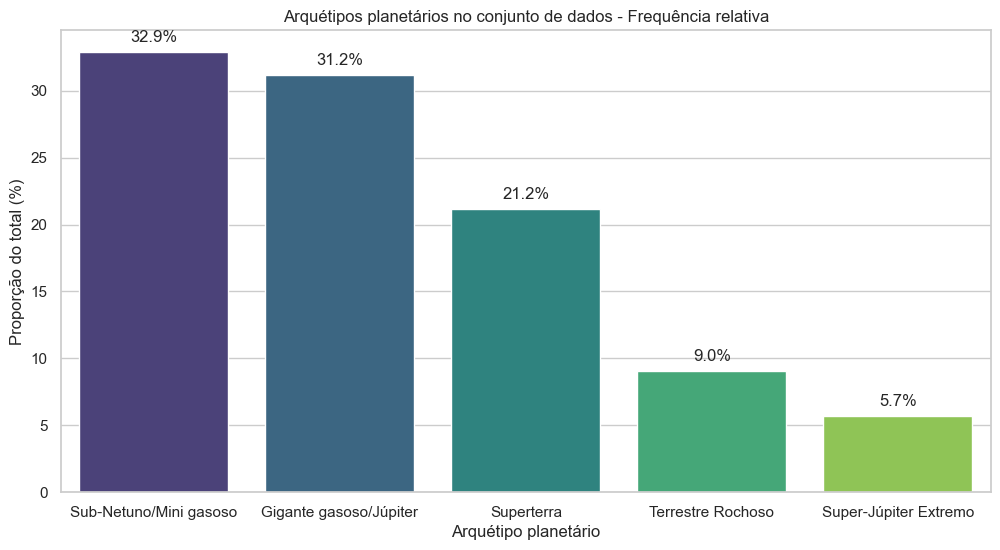

In [127]:
freq_relativa = df['arquetipo_planetario'].value_counts(normalize=True) * 100
df_perc = freq_relativa.reset_index()
df_perc.columns = ['arquetipo_planetario', 'porcentagem']

df_perc['arquetipo_planetario'] = df_perc['arquetipo_planetario'].astype(str)

plt.figure(figsize=(12, 6))

ay = sns.barplot(
    data=df_perc,
    x='arquetipo_planetario',
    y='porcentagem',
    order=df_perc['arquetipo_planetario'],
    palette='viridis',
    hue='arquetipo_planetario',
    legend=False,
)

for container in ay.containers:
    ay.bar_label(container, fmt='%.1f%%', padding=5)

plt.title('Arquétipos planetários no conjunto de dados - Frequência relativa')
plt.ylabel('Proporção do total (%)')
plt.xlabel('Arquétipo planetário')

plt.show()

- **zona_habitabilidade_termica:**

  Regime térmico do planeta, o qual pode ser: "Infernal", com temp_equilibrio_superf_planetaria superior a 500 Kelvin; "Morno/Temperado", entre 320 e 500 K; "Gélido/Criogênico", inferior a 200 K; "Zona Habitável Conservadora", de 200 a 320 K.

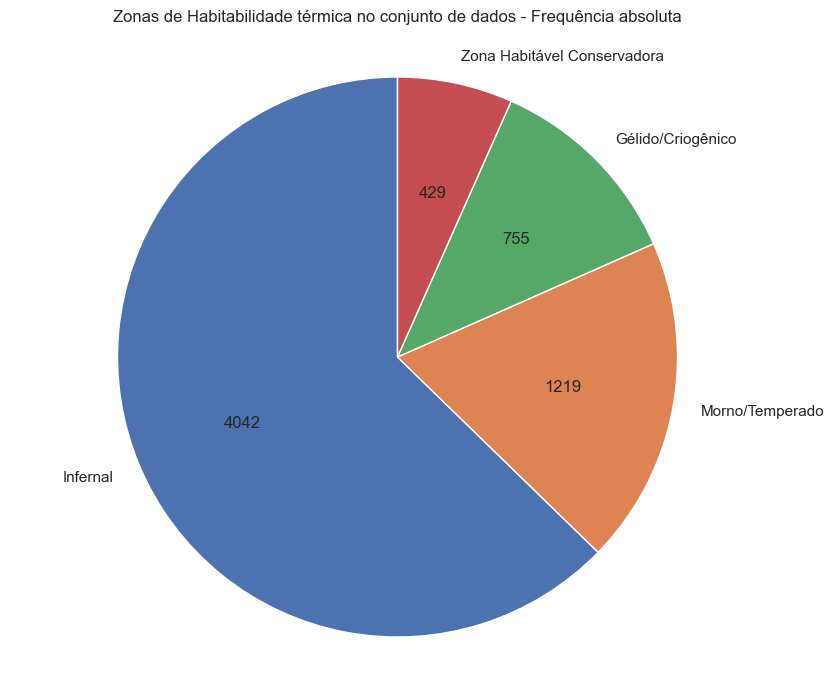

In [128]:
contagem = df['zona_habitabilidade_termica'].value_counts()
total = contagem.sum()

def exibe_valor_absoluto(porcentagem):
    valor_real = int(round(porcentagem * total / 100.0))
    return str(valor_real)

plt.figure(figsize=(10, 8))

plt.pie(
    x=contagem,
    labels=contagem.index,
    autopct=exibe_valor_absoluto,
    startangle=90,
)

plt.title('Zonas de Habitabilidade térmica no conjunto de dados - Frequência absoluta', pad=20)
plt.axis('equal')

plt.show()

- **nivel_arquitetura_orbital:**

  Categoria de dinâmica orbital do planeta, a qual pode ser: "Sistema Interno Compacto", com período orbital de 1 a 10 dias terrestres; "Órbita na Zona Habitável", de 10 a 400 dias; "Sistema Externo Frio", superior a 400 dias; "Período Ultracurto", inferior a 1 dia.

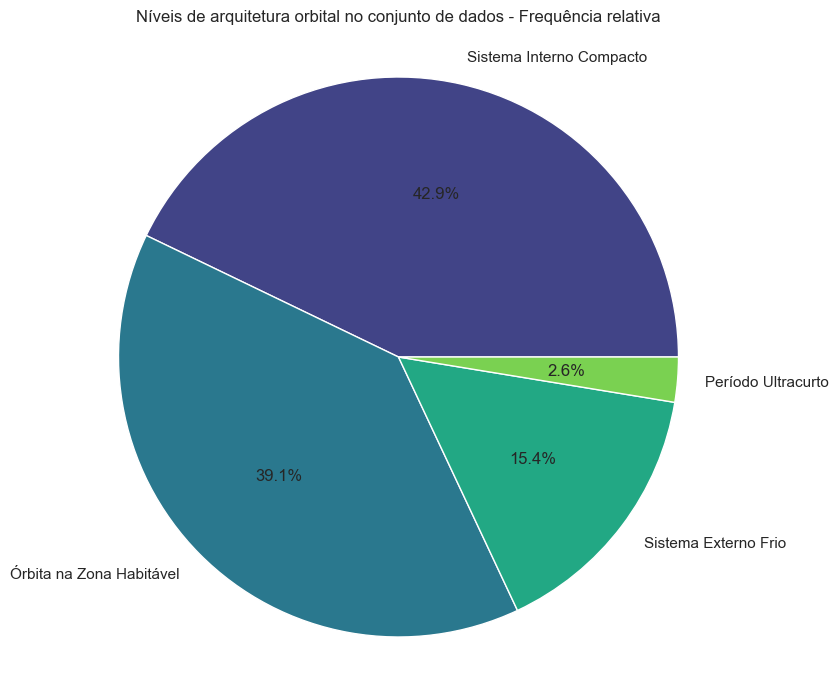

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

contagem = df['nivel_arquitetura_orbital'].value_counts()

plt.figure(figsize=(10, 8))

plt.pie(
    x=contagem,
    labels=contagem.index,
    autopct='%1.1f%%',
    colors=sns.color_palette('viridis', len(contagem))
)

plt.title('Níveis de arquitetura orbital no conjunto de dados - Frequência relativa', pad=20)
plt.axis('equal')

plt.show()

- **classe_estelar:**

  Categoria espectral da estrela, a qual pode ser: "Análoga ao Sol (Anã Classe G)", com temp_superf_estelar de 5200 a 6000 Kelvin; "Anã Laranja (Classe K)", entre 3700 a 5200 K; "Estrela Massiva Quente (Classes F/A)", superior a 6000 K; "Anã Vermelha (Classe M)", inferior a 3700 K.

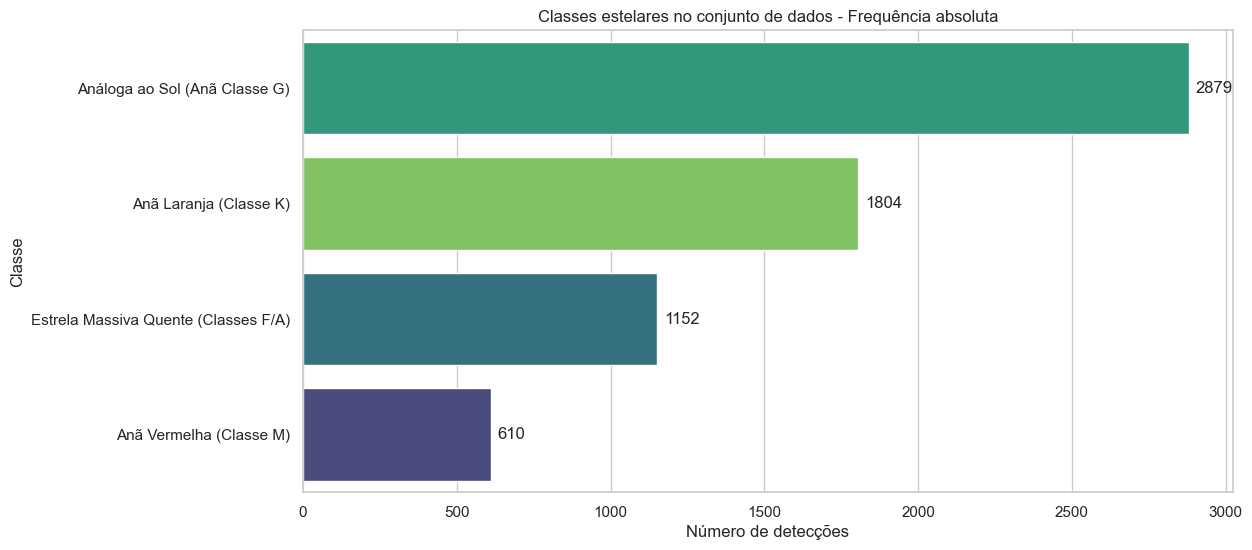

In [130]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df,
    y='classe_estelar',
    order=df['classe_estelar'].value_counts().index,
    palette='viridis',
    hue='classe_estelar',
    legend=False,
)
for container in ax.containers:
    ax.bar_label(container, padding=5)

plt.title('Classes estelares no conjunto de dados - Frequência absoluta')
plt.xlabel('Número de detecções')
plt.ylabel('Classe')

plt.show()

A largura consideravelmente maior da coluna da direita deixa claro que o método de Trânsito é responsável pela grande maioria das descobertas catalogadas; as detecções feitas por Trânsito concentram-se bastante no arquétipo "Sub-Netuno/Mini gasoso", que ocupa a maior área vertical da coluna. Embora o método de Velocidade Radial apresente um volume de descobertas bem menor (associado a uma coluna mais estreita), sua distribuição interna é altamente enviesada para a detecção de "Gigantes gasosos/Júpiter".

## Zonas de habitabilidade térmica

É possível visualizar a relação entre a classificação zona_habitabilidade_termica de um exoplaneta e seus valores de temp_equilibrio_superf_planetaria e periodo_orbital (pela Terceira Lei de Kepler, o período é proporcional a distância do planeta a sua estrela, o que influencia seu em regime térmico). Naturalmente, quanto maior a temperatura da superfície, mais quente é o regime térmico do planeta, também podendo ser relacionado a isso menores períodos orbitais (maior proximidade a estrela orbitada) dos exoplanetas.

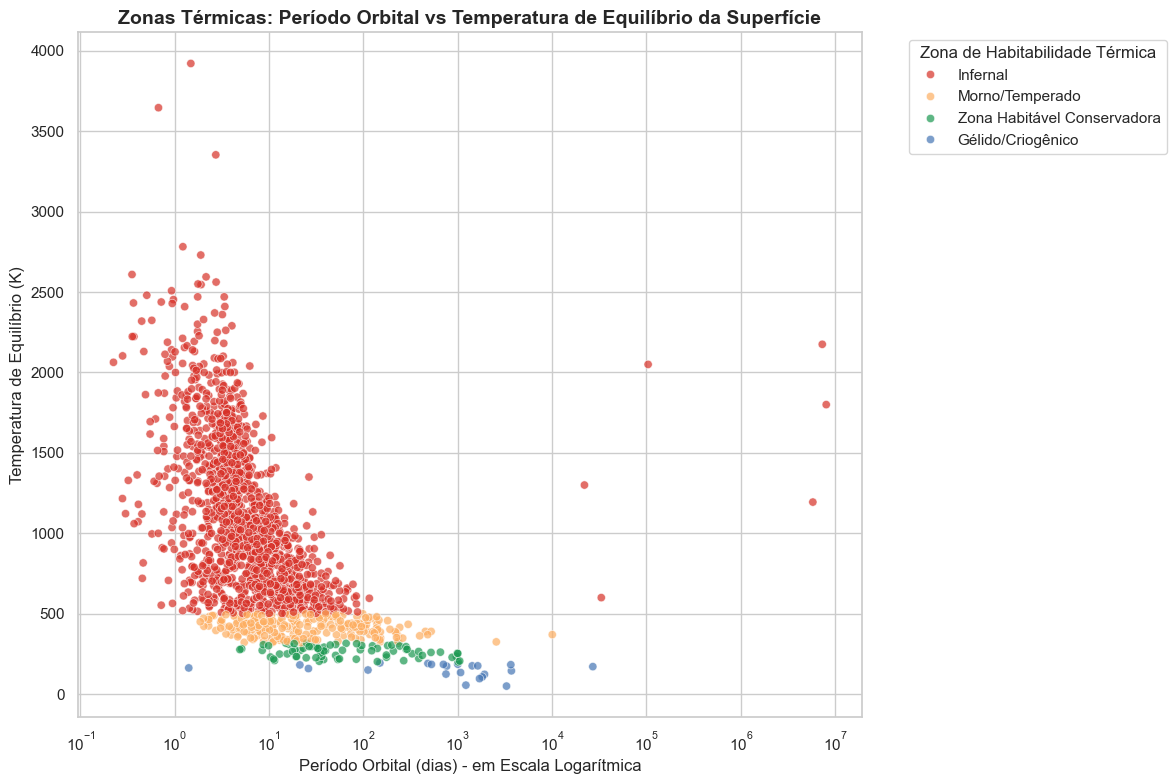

In [131]:
df_plot_termica = df.dropna(subset=[
    'periodo_orbital',
    'temp_equilibrio_superf_planetaria',
    'zona_habitabilidade_termica'
])

plt.figure(figsize=(12, 8))

cores_zonas = {
    'Infernal': '#d73027',                     # Vermelho
    'Morno/Temperado': '#fdae61',              # Laranja
    'Zona Habitável Conservadora': '#1a9850',  # Verde
    'Gélido/Criogênico': '#4575b4'             # Azul
}

sns.scatterplot(
    data=df_plot_termica,
    x='periodo_orbital',
    y='temp_equilibrio_superf_planetaria',
    hue='zona_habitabilidade_termica',
    palette=cores_zonas,
    alpha=0.7,
    edgecolor='w',
    linewidth=0.5
)

plt.title('Zonas Térmicas: Período Orbital vs Temperatura de Equilíbrio da Superfície', fontsize=14, weight='bold')
plt.xlabel('Período Orbital (dias) - em Escala Logarítmica')
plt.ylabel('Temperatura de Equilíbrio (K)')

plt.xscale('log')

plt.legend(title='Zona de Habitabilidade Térmica', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## Arquétipos Planetários

Como existem milhares de planetas descobertos e cada um tem características diferentes, os astrônomos costumam agrupá-los em tipos chamados de arquétipos planetários. Essa divisão é feita principalmente com base no tamanho (raio) e no peso (massa) do planeta, comparando sempre com a Terra ou com Júpiter.

Os cinco grupos principais são:
- Terrestre Rochoso: planetas parecidos com a Terra, Mercúrio ou Marte.
- Superterra: planetas rochosos, mas um pouco maiores que a Terra.
- Sub-Netuno / Mini gasoso: planetas menores que Netuno, com uma atmosfera de gás espessa.
- Gigante gasoso / Júpiter: planetas muito grandes formados quase só por gás.
- Super-Júpiter Extremo: planetas gigantescos, muito maiores e mais pesados que Júpiter.

Abaixo, vemos a contagem de quantos planetas foram encontrados em cada um desses grupos.

In [132]:
freq_abs = df['arquetipo_planetario'].value_counts()
freq_rel = df['arquetipo_planetario'].value_counts(normalize=True).round(3)

tabela_arquetipos = pd.DataFrame({
    'Arquétipo Planetário': freq_abs.index,
    'Frequência Absoluta': freq_abs.values,
    'Frequência Relativa': (freq_rel.values * 100).round(1).astype(str) + '%'
})

fig_freq = go.Figure(data=[go.Table(
    header=dict(
        values=[f'<b>{col}</b>' for col in tabela_arquetipos.columns],
        fill_color='#2c3e50',
        font=dict(color='white', size=13),
        align='center',
        height=32
    ),
    cells=dict(
        values=[tabela_arquetipos[col] for col in tabela_arquetipos.columns],
        fill_color=[['#f8f9fa', '#ffffff'] * len(tabela_arquetipos)],
        font=dict(color='#2c3e50', size=12),
        align=['left', 'center', 'center'],
        height=28
    )
)])

fig_freq.update_layout(
    title='Tabela de Frequência: Arquétipos Planetários',
    title_x=0.5,
    width=650,
    height=280,
    margin=dict(l=20, r=20, t=50, b=20)
)

fig_freq.show()

### Relação entre o Tipo de Planeta e o Clima (Zona Térmica)

Aqui cruzamos o tipo do planeta com a sua temperatura estimada para responder: onde esses planetas estão localizados em relação à estrela?

Olhando os dados da tabela, podemos notar alguns pontos importantes:
- A maioria esmagadora dos planetas descobertos está nas categorias "Infernal" ou "Morno", ou seja, muito perto da estrela onde faz muito calor.
- A "Zona Habitável" (onde a água líquida poderia existir) tem pouquíssimos planetas. 
- A maioria dos planetas na zona habitável são gigantes gasosos ou sub-netunos. Isso significa que, mesmo na temperatura certa, eles não têm uma superfície sólida como a Terra para pisar.

In [133]:
tab_cont = pd.crosstab(
    df['arquetipo_planetario'],
    df['zona_habitabilidade_termica'],
    margins=True,
    margins_name='Total'
).reset_index()

tab_cont = tab_cont.rename(columns={'arquetipo_planetario': 'Arquétipo Planetário'})

fig_cont = go.Figure(data=[go.Table(
    columnwidth=[220, 140, 110, 140, 190, 100],  # Garante largura para o nome não quebrar errado
    header=dict(
        values=[f'<b>{col}</b>' for col in tab_cont.columns],
        fill_color='#2c3e50',
        font=dict(color='white', size=13),
        align='center',
        height=34
    ),
    cells=dict(
        values=[tab_cont[col] for col in tab_cont.columns],
        fill_color=[['#f8f9fa', '#ffffff'] * len(tab_cont)],
        font=dict(color='#2c3e50', size=12),
        align=['left'] + ['center'] * (len(tab_cont.columns) - 1),
        height=36  # Altura suficiente para exibir o texto e os números sem cortar
    )
)])

fig_cont.update_layout(
    title='Tabela de Contingência: Arquétipo vs Zona de Habitabilidade Térmica',
    title_x=0.5,
    width=950,
    height=340,
    margin=dict(l=20, r=20, t=50, b=20)
)

fig_cont.show()

### Comparando a Massa dos Planetas e Encontrando Casos Estranhos

O gráfico de caixas (boxplot) mostra como a massa varia dentro de cada grupo. O esperado é que planetas terrestres sejam leves e gigantes gasosos sejam muito pesados. 

No entanto, no gráfico podemos ver alguns pontos bem distantes da caixa principal. Esses pontos são chamados de outliers (valores fora da curva).

Um caso muito curioso é o planeta **KOI-2513.01**:
- Pelo seu tamanho (raio), ele foi classificado como um Sub-Netuno.
- Mas quando olhamos a sua massa, ele é incrivelmente mais pesado do que os outros planetas do mesmo grupo.
- Isso mostra que ele é um planeta fora do padrão: ele pode ter um núcleo de ferro e rocha muito denso e compacto, em vez de ser formado apenas por gás leve.

In [134]:
cols = ['nome_planeta', 'massa_planetaria', 'raio_planetario', 'arquetipo_planetario']

if set(cols).issubset(df.columns):

    sub = df[cols].dropna()

    sub = sub[
        (sub['massa_planetaria'] > 0) &
        (sub['raio_planetario'] > 0)
    ]

    if not sub.empty:
        fig = px.scatter(
            sub,
            x='massa_planetaria',
            y='raio_planetario',
            color='arquetipo_planetario',
            hover_name='nome_planeta',
            hover_data={
                'massa_planetaria': ':.2f',
                'raio_planetario': ':.2f',
                'arquetipo_planetario': True
            },
            log_x=True,
            log_y=True,
            opacity=0.5,
            title='Massa × Raio por arquétipo planetário',
            labels={
                'massa_planetaria': 'Massa planetária (Massas terrestres)',
                'raio_planetario': 'Raio planetário (Raios terrestres)',
                'arquetipo_planetario': 'Arquétipo planetário'
            },
            template='plotly_white'
        )

        fig.update_traces(
            marker=dict(size=7)
        )

        fig.update_xaxes(dtick=1)
        fig.update_yaxes(dtick=1)

        fig.update_layout(
            width=1100,
            height=700,
            title_x=0.5,
            legend=dict(
                title='Arquétipo planetário',
                x=1.02,
                y=1,
                xanchor='left',
                yanchor='top'
            ),
            margin=dict(l=70, r=200, t=80, b=70)
        )

        fig.show()

In [135]:
df_box = df.dropna(subset=['arquetipo_planetario', 'massa_planetaria', 'nome_planeta'])
df_box = df_box[df_box['massa_planetaria'] > 0]

fig = px.box(
    df_box,
    x='arquetipo_planetario',
    y='massa_planetaria',
    color='arquetipo_planetario',
    hover_name='nome_planeta',
    log_y=True,
    title='Distribuição de Massa por Arquétipo Planetário',
    labels={
        'arquetipo_planetario': 'Arquétipo planetário',
        'massa_planetaria': 'Massa planetária (Massas terrestres)'
    },
    template='plotly_white'
)

fig.update_yaxes(dtick=1)

fig.update_layout(
    width=1000,
    height=1000,
    title_x=0.5,
    showlegend=False
)

fig.show()

In [136]:
planeta_outlier = df[df['nome_planeta'] == 'KOI-2513.01']
planeta_outlier.T

,957
nome_planeta,KOI-2513.01
nome_estrela_primaria,KOI-2513
metodo_descoberta,Trânsito
ano_descoberta,2023
observatorio_descoberta,Kepler
periodo_orbital,19.00547
raio_planetario,2.802245
massa_planetaria,7310.053361
temp_equilibrio_superf_planetaria,NaN
temp_superf_estelar,5900.0


### O Tamanho dos Planetas Varia Conforme o Método Usado?

Cada telescópio e técnica de caça aos planetas tem facilidade para achar um tipo específico de corpo. Chamamos isso de viés do instrumento.

Observando o gráfico:
- **Trânsito:** Consegue achar desde planetas bem pequenos até gigantes. Ele mede a sombra do planeta passando na frente da estrela, por isso é o melhor método para medir o raio.
- **Velocidade Radial:** Acha planetas medindo o quanto a estrela balança pela gravidade. Esse método calcula a massa, mas quase não consegue medir o raio sozinho.
- **Outros (como Imagem Direta):** Só aparecem com raios enormes (10 a 100 vezes o tamanho da Terra). Tirar foto de um planeta é muito difícil, então só conseguimos ver planetas gigantescos e brilhantes.
- **Microlente Gravitacional:** O método não tem nenhuma barra no gráfico (fica em branco). Isso acontece porque ele usa a gravidade para achar o planeta, sem medir o tamanho físico dele. A ausência de dados aqui não significa que os planetas não existem, e sim que esse método não consegue medir o raio.

In [137]:
df_raio = df.dropna(subset=['metodo_descoberta', 'raio_planetario'])
df_raio = df_raio[df_raio['raio_planetario'] > 0]

todos_metodos = df['metodo_descoberta'].dropna().unique().tolist()

fig_raio = px.box(
    df_raio,
    x='metodo_descoberta',
    y='raio_planetario',
    color='metodo_descoberta',
    hover_name='nome_planeta',
    category_orders={'metodo_descoberta': todos_metodos},
    log_y=True,
    title='Distribuição do Raio Planetário por Método de Descoberta',
    labels={
        'metodo_descoberta': 'Método de Descoberta',
        'raio_planetario': 'Raio Planetário (Raios Terrestres)'
    },
    template='plotly_white'
)

fig_raio.update_traces(marker=dict(size=6))

fig_raio.update_yaxes(
    dtick=1,
    tickvals=[0.1, 1, 10, 100],
    ticktext=['0.1', '1', '10', '100']
)

fig_raio.update_layout(
    width=1100,
    height=600,
    title_x=0.5,
    showlegend=False
)

fig_raio.show()

### Quanto Tempo Leva o Ano de Cada Planeta?

O período orbital é o tempo que o planeta leva para dar uma volta completa ao redor da sua estrela (o equivalente ao nosso ano).

Comparando os tipos de planetas:
- **Terrestres e Superterras:** Têm anos curtíssimos. A mediana fica em torno de 4 a 7 dias. Ou seja, em uma semana o planeta já completou um ano inteiro.
- **Sub-Netunos e Gigantes:** Ficam mais espalhados, levando de semanas até vários meses para completar uma volta.
- **Super-Júpiteres:** Mostram dois extremos. Temos desde planetas colados na estrela que orbitam em menos de 3 dias, até gigantes que levam milhares de dias (vários anos terrestres) para dar uma volta.

In [138]:
df_periodo = df.dropna(subset=['arquetipo_planetario', 'periodo_orbital'])
df_periodo = df_periodo[df_periodo['periodo_orbital'] > 0]

fig_periodo = px.box(
    df_periodo,
    x='arquetipo_planetario',
    y='periodo_orbital',
    color='arquetipo_planetario',
    hover_name='nome_planeta',
    log_y=True,
    title='Distribuição do Período Orbital por Arquétipo Planetário',
    labels={
        'arquetipo_planetario': 'Arquétipo Planetário',
        'periodo_orbital': 'Período Orbital (Dias)'
    },
    template='plotly_white'
)

fig_periodo.update_traces(marker=dict(size=6))

fig_periodo.update_yaxes(
    dtick=1,
    tickvals=[0.1, 1, 10, 100, 1000, 10000, 100000],
    ticktext=['0.1 d', '1 d', '10 d', '100 d', '1.000 d', '10.000 d', '100.000 d']
)

fig_periodo.update_layout(
    width=1000,
    height=650,
    title_x=0.5,
    showlegend=False
)

fig_periodo.show()

### Qual Método Encontra Cada Tipo de Planeta?

Comparando as barras de cada arquétipo, conseguimos ver com clareza a especialidade de cada técnica:

- **Trânsito:** É o único método capaz de encontrar grandes quantidades de planetas menores, dominando as descobertas de Sub-Netunos (1.884), Superterras (1.143) e Terrestres Rochosos (540). Como ele mede a sombra do planeta na estrela, sua sensibilidade é excelente para medir o tamanho de corpos pequenos.
- **Velocidade Radial:** Sua grande maioria de descobertas está concentrada nos Gigantes gasosos (737 planetas). Como ele depende da força da gravidade que o planeta faz na estrela, planetas muito pesados como Júpiter são muito mais fáceis de detectar por essa técnica do que planetas leves como a Terra (apenas 33 detecções).
- **Microlente e Outros:** Encontram quase exclusivamente Gigantes gasosos e Super-Júpiteres, que geram efeitos de lente gravitacional mais fortes ou emitem luz própria suficiente para serem fotografados.

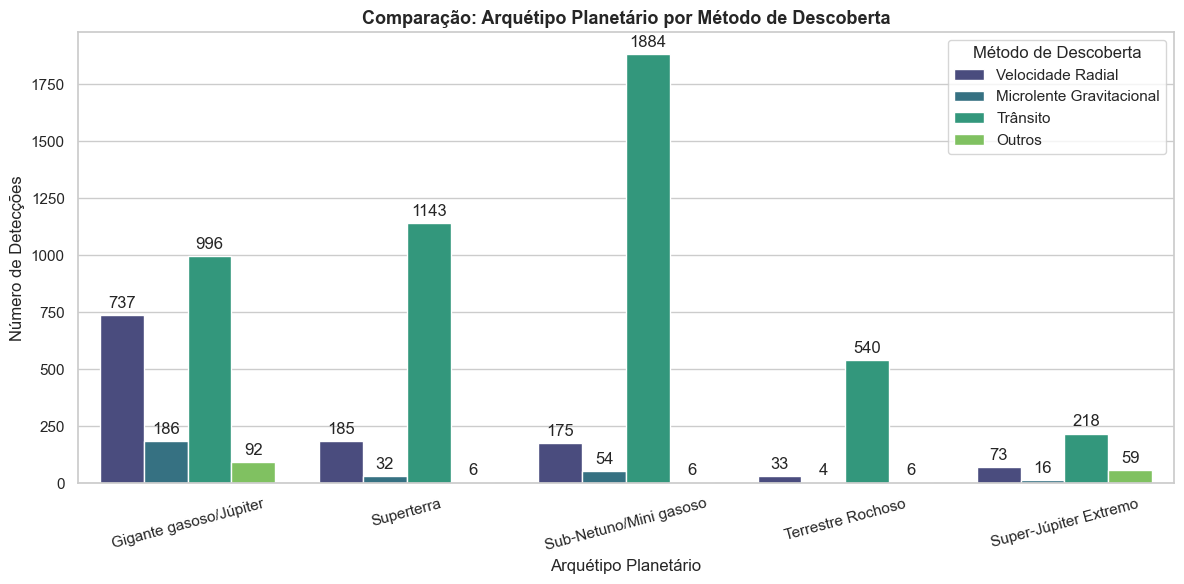

In [139]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df,
    x='arquetipo_planetario',
    hue='metodo_descoberta',
    palette='viridis'
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Comparação: Arquétipo Planetário por Método de Descoberta', fontsize=13, weight='bold')
plt.xlabel('Arquétipo Planetário')
plt.ylabel('Número de Detecções')
plt.xticks(rotation=15)
plt.legend(title='Método de Descoberta')
plt.tight_layout()
plt.show()

### Como os Métodos de Descoberta Mudaram ao Longo do Tempo

Este gráfico mostra a porcentagem de planetas descobertos por cada método em cada ano:

- **Até 2003:** Praticamente todas as descobertas eram feitas por **Velocidade Radial** (medindo o balanço da estrela a partir de observatórios na Terra).
- **A partir de 2010 (explosão azul no gráfico):** O método do **Trânsito** passou a dominar completamente o cenário, sendo responsável por 70% a 90% das descobertas anuais. Essa mudança radical aconteceu por causa do lançamento de telescópios espaciais como o Kepler e o TESS, que observavam milhares de estrelas ao mesmo tempo procurando a sombra dos planetas.
- **Microlente Gravitacional e Outros (faixas verde e laranja):** Mantêm participações menores, mas constantes, ajudando a encontrar planetas em situações onde o Trânsito não consegue atuar.

In [140]:
cols = ['ano_descoberta', 'metodo_descoberta']

if set(cols).issubset(df.columns):

    sub = df[cols].dropna().copy()

    sub['ano_descoberta'] = pd.to_numeric(
        sub['ano_descoberta'],
        errors='coerce'
    )

    sub = sub.dropna()
    sub = sub[sub['ano_descoberta'] >= 1995]

    top = sub['metodo_descoberta'].value_counts().head(5).index

    sub['metodo_grupo'] = sub['metodo_descoberta'].where(
        sub['metodo_descoberta'].isin(top),
        'Outros'
    )

    tab = pd.crosstab(
        sub['ano_descoberta'].astype(int),
        sub['metodo_grupo'],
        normalize='index'
    )

    if not tab.empty:

        # Converter para formato longo
        tab_long = (
            tab.reset_index()
            .melt(
                id_vars='ano_descoberta',
                var_name='Método de descoberta',
                value_name='Proporção'
            )
        )

        # Gráfico de áreas empilhadas
        fig = px.area(
            tab_long,
            x='ano_descoberta',
            y='Proporção',
            color='Método de descoberta',
            color_discrete_sequence=px.colors.qualitative.Set2,
            title='Composição Anual dos Métodos de Descoberta',
            labels={
                'ano_descoberta': 'Ano de descoberta',
                'Proporção': 'Proporção de descobertas'
            },
            template='plotly_white'
        )

        # Personalização
        fig.update_layout(
            width=1200,
            height=650,
            title=dict(
                x=0.5,
                font=dict(size=20)
            ),
            xaxis=dict(
                title='Ano de descoberta',
                dtick=2,
                tickformat='d'
            ),
            yaxis=dict(
                title='Proporção de descobertas',
                tickformat='.0%',
                range=[0, 1]
            ),
            legend=dict(
                title='Método de descoberta',
                x=1.02,
                y=1,
                xanchor='left',
                yanchor='top'
            ),
            hovermode='x unified',
            margin=dict(l=70, r=220, t=80, b=70)
        )

        fig.update_traces(
            hovertemplate=(
                'Ano: %{x}<br>'
                'Proporção: %{y:.2%}'
                '<extra>%{fullData.name}</extra>'
            )
        )

        fig.show()

        # Salvar versão interativa
        fig.write_html('composicao_anual_metodos.html')